Etapa 1: Contextualização e Formulação da Pergunta
Apresente a origem dos dados, o contexto temático e a relevância do problema
investigado.

(escrever)

Declare formalmente a variável alvo () que você deseja prever e descreva o
significado de cada uma das variáveis de entrada () selecionadas.

(escrever)

Justifique formalmente a escolha do tipo de aprendizado (Regressão ou
Classificação), conectando-a à natureza da variável de saída.

(escrever)

O nosso problema analítico exige uma abordagem de Regressão, já que o que será analisado é: 'O que faz uma música ter uma alta danceability?'
E nesse caso era iria prever o quanto a música(x) tem de danceability.  (rascunho)

In [2]:

pip install pandas numpy matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

Etapa 2: Exploração e Engenharia de Dados

In [ ]:
df=pd.read_csv('songs_normalize.csv')
display(df.head()) #exibindo as primeiras 5 linhas

In [ ]:

#verificando o tamanho da base
print("Linhas e colunas:", df.shape)
#verificando os tipos das colunas
print(df.dtypes)

In [ ]:
#valores nulos
print(df.isnull().sum())

In [7]:
#verificando linhas duplicadas
print("Linhas duplicadas:", df.duplicated().sum())

Linhas duplicadas: 59


In [8]:
#removendo linhas duplicadas
df = df.drop_duplicates()
#verificando linhas duplicadas(novamente)
print("Linhas duplicadas:", df.duplicated().sum())

Linhas duplicadas: 0


Etapa 3: Particionamento dos Dados (Treino e Teste)

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('Dados de treino:', X_train.shape[0])
print('Dados de teste:', X_test.shape[0])

Dados de treino: 1552
Dados de teste: 389


Etapa 4: Construção e Treinamento do Modelo

In [29]:

modelo = LinearRegression()
modelo.fit(X_treino, y_treino)

print("Intercepto:", modelo.intercept_)

coeficientes = pd.DataFrame({
    'Variável': X.columns,
    'Coeficiente': modelo.coef_
})

display(coeficientes.sort_values(
    by='Coeficiente',
    key=abs,
    ascending=False
))


Intercepto: -5.777054456072466


,Variável,Coeficiente
11,valence,3.129473e-01
3,energy,-2.465857e-01
7,speechiness,1.833749e-01
8,acousticness,-1.334101e-01
10,liveness,-1.015363e-01
9,instrumentalness,8.992448e-02
6,mode,-9.810316e-03
1,year,3.262845e-03
12,tempo,-8.502674e-04
4,key,-4.446527e-04


Etapa 5: Avaliação Quantitativa e Diagnóstico Visual

R²: 0.2532
MAE: 0.0977
RMSE: 0.1245


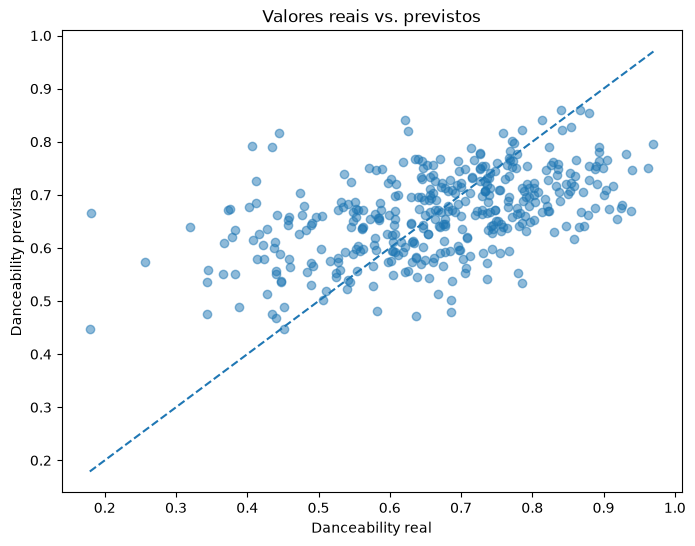

In [31]:

# Realizando previsões
y_previsto = modelo.predict(X_teste)

# Calculando as métricas
r2 = r2_score(y_teste, y_previsto)
mae = mean_absolute_error(y_teste, y_previsto)
rmse = np.sqrt(mean_squared_error(y_teste, y_previsto))

print(f"R²: {r2:.4f}")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

# Gráfico de valores reais versus previstos
plt.figure(figsize=(8, 6))
plt.scatter(y_teste, y_previsto, alpha=0.5)

limite_min = min(y_teste.min(), y_previsto.min())
limite_max = max(y_teste.max(), y_previsto.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle='--'
)

plt.xlabel('Danceability real')
plt.ylabel('Danceability prevista')
plt.title('Valores reais vs. previstos')
plt.show()


Etapa 6: Simulador Interativo (Inferência com Entrada do Usuário)

Etapa 7: Discussão Crítica e Conclusões

1. Interpretação das Métricas: O que os resultados numéricos revelam sobre a
eficácia prática do modelo? Ele é confiável para tomada de decisão real?

O modelo apresentou R^2 de 0,2532, MAE de 0,0977 e o RMSE de 0,1245, mostrando que existem diferenças entre os valores reais e previstos. Portanto, o modelo possui capacidade limitada de previsão e precisa ser aprimorado antes de ser utilizado em decisões reais.

2. Diagnóstico dos Erros:

○ Caso Regressão: A diferença entre MAE e RMSE aponta presença de
desvios atípicos acentuados? O que o peso de cada variável revela sobre a
importância delas?

O RMSE foi superior ao MAE, sugerindo que alguns erros maiores influenciam o desempenho do modelo. Os coeficientes da Regressão Linear permitem analisar como cada variável influencia as previsões, identificando associações positivas ou negativas com a dançabilidade.

3. Limitações: Quais fatores ou variáveis adicionais não presentes na sua base
original poderiam elevar a precisão do sistema se estivessem disponíveis?

A precisão do modelo poderia melhorar com a inclusão de outras características musicais, como ritmo, estrutura da música, padrões de batida e informações sobre a percepção dos ouvintes. Além disso, outros algoritmos poderiam ser testados para comparar os resultados e buscar previsões mais precisas.